In [1]:
#a small example

import pandas as pd

data= {
    "income": [3, 4, 15, 18, 3.5, 20],
    "spending_score": [85, 90, 20, 15, 80, 10]
}
df= pd.DataFrame(data)
df.head()

,income,spending_score
0,3.0,85
1,4.0,90
2,15.0,20
3,18.0,15
4,3.5,80


In [2]:
#select features, rember we don't have lable values
X= df[["income", "spending_score"]]

In [4]:
#We're giving the algorithm two features to discover groups.
from sklearn.cluster import KMeans

km = KMeans(
    n_clusters=2,    
    random_state=42,
    n_init=10
)

km.fit(X)

C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=2, n_init=10, random_state=42)

In [5]:
#Get cluster assignments
df["cluster"] = km.labels_

print(df)

#Cluster numbers are arbitrary. Cluster 0 isn't inherently better than Cluster 1.

   income  spending_score  cluster
0     3.0              85        1
1     4.0              90        1
2    15.0              20        0
3    18.0              15        0
4     3.5              80        1
5    20.0              10        0


In [6]:
#Find the centroids
print(km.inertia_)

113.16666666666667


In [7]:
#Check inertia
print(km.inertia_)

113.16666666666667


##### One very important thing: Feature Scaling
Our example has two features:
- Income: values between 3 and 20.
- Spending score: values between 10 and 90.
Notice that spending score has a larger numerical range.

Since K-Means uses distance calculations, features with larger numerical scales can dominate the distance.

We should generally scale our features before applying K-Means.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

km = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

km.fit(X_scaled)

df["cluster"] = km.labels_

C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


##### StandardScaler transforms features to have approximately:
- Mean = 0
- Standard deviation = 1
This makes the features more comparable when calculating distances.

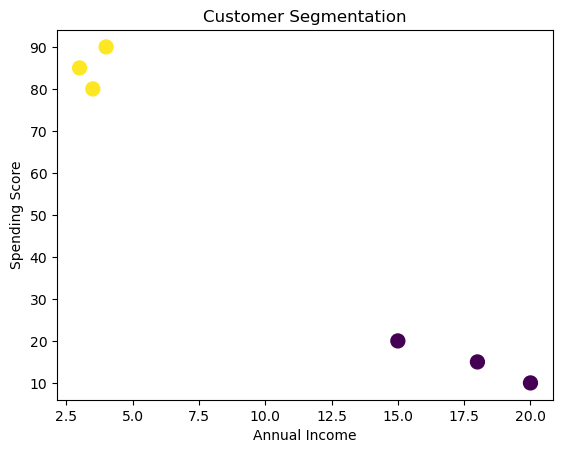

In [12]:
import matplotlib.pyplot as plt

plt.scatter(
    X["income"],
    X["spending_score"],
    c=df["cluster"],
    cmap="viridis",
    s=100
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.show()